In [1]:
import sys

sys.path.append("..")

from pathlib import Path
from datetime import datetime
import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from classes.sample.sample_classes import SampleWaveletPacket
from tqdm import tqdm

In [2]:
from lib.wpt_utils import (
    load_wavelets,
    build_index_per_level,
)

In [3]:
from copy import deepcopy

# Load data

In [4]:
SEQ_1_PATH = Path("../data/wpts/sequence_1_db35")
SEQ_2_PATH = Path("../data/wpts/sequence_2_db35")
SEQ_3_PATH = Path("../data/wpts/sequence_3_db35")

In [5]:
SEQ_1_HEALTH_END = datetime(2023, 1, 25, 10, 0, 0)
SEQ_2_HEALTH_END = datetime(2023, 5, 9, 11, 0, 0)
SEQ_3_HEALTH_END = datetime(2023, 8, 30, 11, 0, 0)

CABLES = [1, 2, 3, 4]
AXES = ["x", "y", "z"]

In [6]:
data_valid = load_wavelets(SEQ_1_PATH)
data_train = load_wavelets(SEQ_2_PATH)

100%|██████████| 6210/6210 [02:57<00:00, 34.94it/s]


# Prepare data

In [7]:
def prepare_dicts(data_list: list[SampleWaveletPacket]) -> tuple[dict, dict]:
    y = {}
    z = {}
    t = {}
    dates = []
    CABLES = [1, 2, 3, 4]
    for cable in CABLES:
        key = f"sample_c{cable}"
        y[cable] = []
        z[cable] = []
        t[cable] = []
        for data in data_list:
            sample = data.__getattribute__(key)
            if cable == 1:
                dates.append(datetime.fromisoformat(data.sample_id))
            y[cable].append(sample.y.energy_map)
            z[cable].append(sample.z.energy_map)
            t[cable].append(sample.tension)
        y[cable] = np.array(y[cable])
        z[cable] = np.array(z[cable])
        t[cable] = np.array(t[cable])

    # get chronological order
    idx_date = np.argsort(dates)

    # sort data
    y = {cable: y[cable][idx_date] for cable in CABLES}
    z = {cable: z[cable][idx_date] for cable in CABLES}
    t = {cable: t[cable][idx_date] for cable in CABLES}

    # get radial
    r = {cable: np.sqrt(y[cable] ** 2 + z[cable] ** 2) for cable in CABLES}

    return r, t

In [8]:
r_train, t_train = prepare_dicts(data_train)
r_valid, t_valid = prepare_dicts(data_valid)

In [9]:
index_per_level = build_index_per_level(0, 9)

In [10]:
# min max norm by layer

def normalize_dict_minmax(
    raw: dict[str, np.ndarray], index_per_level: dict[int, list[int]]
) -> dict[str, np.ndarray]:
    norm = {}
    for c in [1, 2, 3, 4]:
        temp = []
        for _, ind in index_per_level.items():
            if len(ind) == 1:
                ind = [0]
                xn = np.ones_like(raw[c][:, ind])
            else:
                x = raw[c][:, ind]
                xn = (x - x.min(axis=1, keepdims=True)) / (
                    x.max(axis=1, keepdims=True) - x.min(axis=1, keepdims=True)
                )
            temp.append(xn)
        norm[c] = np.hstack(temp)
    return norm

In [11]:
def normalize_dict_bandwidth(
    raw: dict[str, np.ndarray], index_per_level: dict[int, list[int]]
) -> dict[str, np.ndarray]:
    norm = {}
    for c in [1, 2, 3, 4]:
        temp = []
        for _, ind in index_per_level.items():
            bandwidth = 128 / len(ind)
            if len(ind) == 1:
                ind = [0]
                xn = np.ones_like(raw[c][:, ind])
            else:
                x = raw[c][:, ind]
                xn = x / bandwidth
            temp.append(xn)
        norm[c] = np.hstack(temp)
    return norm

In [12]:
r_train_norm = normalize_dict_minmax(r_train, index_per_level)
r_valid_norm = normalize_dict_minmax(r_valid, index_per_level)

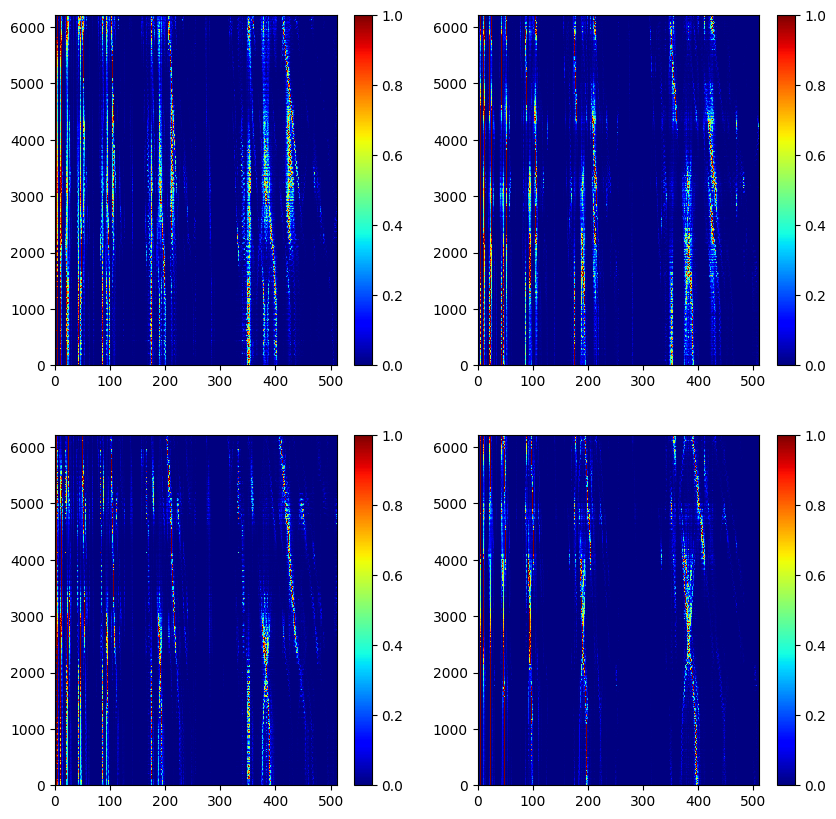

In [13]:
plt.figure(figsize=(10,10))
for cable in [1,2,3,4]:
    plt.subplot(2,2,cable)
    plt.pcolormesh(r_train_norm[cable], cmap="jet", vmin=0)
    plt.colorbar()

# Dataset and Dataloader

In [14]:
# dataset class

class Dataset(torch.utils.data.Dataset):
    def __init__(self, data: dict[int, np.ndarray]):
        self.data = torch.Tensor(np.stack([v for _, v in data.items()], axis=1))
        assert self.data.ndim == 3
        assert self.data.shape[1] == 4

    def __len__(self):
        return len(self.data) - 1

    def __getitem__(self, idx):
        return self.data[[idx, idx + 1], :, :]

In [15]:
train_stacked = np.vstack([r_train_norm[c] for c in [1,2,3,4]])
mu_train = train_stacked.mean(axis=0)
std_train = train_stacked.std(axis=0) + 1e-6

In [16]:
train_dataset = Dataset(r_train_norm)
valid_dataset = Dataset(r_valid_norm)

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)

train_dataloader_no_shuffle = DataLoader(train_dataset, batch_size=32, shuffle=False)
valid_dataloader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

# Model

In [17]:
class Autoencoder(torch.nn.Module):
    def __init__(self, input_dim: int, latent_dim: int):
        super(Autoencoder, self).__init__()
        self.encoder = torch.nn.Sequential(
            torch.nn.Dropout(0.5),
            torch.nn.Linear(input_dim, 128),
            torch.nn.LeakyReLU(),
            # torch.nn.Dropout(0.2),
            torch.nn.Linear(128, 64),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(64, 64),
            torch.nn.LeakyReLU(),
            # torch.nn.Dropout(0.2),
            torch.nn.Linear(64, latent_dim),
        )

        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(latent_dim, 64),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(64, 64),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(64, 128),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(128, input_dim),
            torch.nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)

In [18]:
class VAE(torch.nn.Module):
    def __init__(self, input_dim: int, latent_dim: int):
        super(VAE, self).__init__()
        self.encoder = torch.nn.Sequential(
            #torch.nn.Dropout(0.5),
            torch.nn.Linear(input_dim, 128),
            torch.nn.LeakyReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(128, 64),
            torch.nn.LeakyReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(64, 64),
            torch.nn.LeakyReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(64, 2 * latent_dim),
        )

        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(latent_dim, 64),
            #torch.nn.Dropout(0.2),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(64, 64),
            #torch.nn.Dropout(0.2),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(64, 128),
            #torch.nn.Dropout(0.2),
            torch.nn.LeakyReLU(),
            torch.nn.Linear(128, input_dim),
            # torch.nn.Sigmoid(),
        )

    def encode(self, x):
        mu_logvar = self.encoder(x)
        mu, logvar = torch.chunk(mu_logvar, 2, dim=-1)
        return mu, logvar

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return mu, logvar, self.decode(z)

In [19]:
def level_emd_loss(
    y_true: torch.Tensor, y_pred: torch.Tensor, index_per_level: dict[int, list[int]]
) -> torch.Tensor:
    loss = 0
    for _, ind in index_per_level.items():
        if len(ind) == 1:
            continue
        ref = y_true[:, ind]
        targ = y_pred[:, ind]
        ref_cdf = ref.cumsum(axis=1) / ref.sum(axis=1, keepdims=True)
        targ_cdf = targ.cumsum(axis=1) / targ.sum(axis=1, keepdims=True)
        loss += (ref_cdf - targ_cdf).abs().mean()
    return loss

In [20]:
def kl_divergence_loss(mu: torch.Tensor, logvar: torch.Tensor):
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

In [21]:
def cable_closeness_loss(z: torch.Tensor) -> torch.Tensor:
    assert z.dim() == 3
    z_dist = torch.cdist(z, z, p=2)
    upper_triangular = torch.triu(z_dist, diagonal=1)
    dist_loss = upper_triangular.sum() / (z_dist.shape[0] + z_dist.shape[1])
    return dist_loss

In [30]:
from torch.utils.tensorboard import SummaryWriter

In [31]:
# training loop

input_dim = r_train_norm[1].shape[1]
latent_dim = 8
num_epochs = 500
a = 1
b = 1e-5
beta = 1e-6

model = VAE(input_dim, latent_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
writer = SummaryWriter()

train_loss = []
train_emd_loss = []
train_cable_loss = []
train_seq_loss = []
train_rec_loss = []
train_kl_loss = []

rec_loss_fn = torch.nn.MSELoss()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

for epoch in tqdm(range(num_epochs)):
    running_seq_loss = 0.0
    running_rec_loss = 0.0
    running_kl_loss = 0.0
    running_loss = 0.0
    for x in train_dataloader:
        x = ((x - torch.Tensor(mu_train)) / torch.Tensor(std_train)).to(device)
        model.train()
        optimizer.zero_grad()
        mu, logvar, x_rec = model.forward(x)

        # losses
        emd_loss = 0
        cable_loss = 0
        seq_loss = 0
        kl_loss = 0
        # rec_loss = torch.nn.functional.binary_cross_entropy(x, x_rec)
        rec_loss = rec_loss_fn(x, x_rec)

        # cable_loss += cable_closeness_loss(z[:, k, :])

        # for cable_idx in [0, 1, 2, 3]:
        #     emd_loss += level_emd_loss(
        #         x[:, k, cable_idx], x_rec[:, k, cable_idx], index_per_level
        #     )

        for cable in [0, 1, 2, 3]:
            seq_loss += torch.nn.functional.mse_loss(mu[:, 0, cable], mu[:, 1, cable])
            kl_loss += kl_divergence_loss(mu[:,0,cable], logvar[:,0,cable])

        if epoch < 0:
            switch = 0
        else:
            switch = 1

        loss = rec_loss + a * seq_loss + switch * beta * kl_loss # + b * cable_loss  # + emd_loss

        loss.backward()
        optimizer.step()

        running_seq_loss += seq_loss.detach().to("cpu").item()
        running_rec_loss += rec_loss.detach().to("cpu").item()
        running_kl_loss += kl_loss.detach().to("cpu").item()
        running_loss += loss.detach().to("cpu").item()

    train_loss.append(running_loss)
    #train_cable_loss.append(cable_loss.item())
    train_seq_loss.append(running_seq_loss)
    train_rec_loss.append(running_rec_loss)
    train_kl_loss.append(running_kl_loss)
    # train_emd_loss.append(emd_loss.item())

    writer.add_scalar("Loss/train", running_loss, epoch)
    writer.add_scalar("Seq Loss/train", running_seq_loss, epoch)
    writer.add_scalar("Rec Loss/train", running_rec_loss, epoch)
    writer.add_scalar("KL Loss/train", running_kl_loss, epoch)
    #writer.add_scalar("Cable Loss/train", cable_loss.item(), epoch)

writer.close()

  0%|          | 0/500 [00:00<?, ?it/s]

100%|██████████| 500/500 [28:39<00:00,  3.44s/it]


In [32]:
model = model.eval()

In [33]:
z_train = []
x_rec_train = []
x_train = []
for x in train_dataloader_no_shuffle:
    x = ((x - torch.Tensor(mu_train)) / torch.Tensor(std_train)).to(device)
    with torch.no_grad():
        z, logvar, x_rec = model.forward(x)
    z_train.append(z.cpu())
    x_rec_train.append(x_rec.cpu())
    x_train.append(x.cpu())

z_train = torch.cat(z_train, dim=0)
x_rec_train = torch.cat(x_rec_train, dim=0)
x_train = torch.cat(x_train, dim=0)

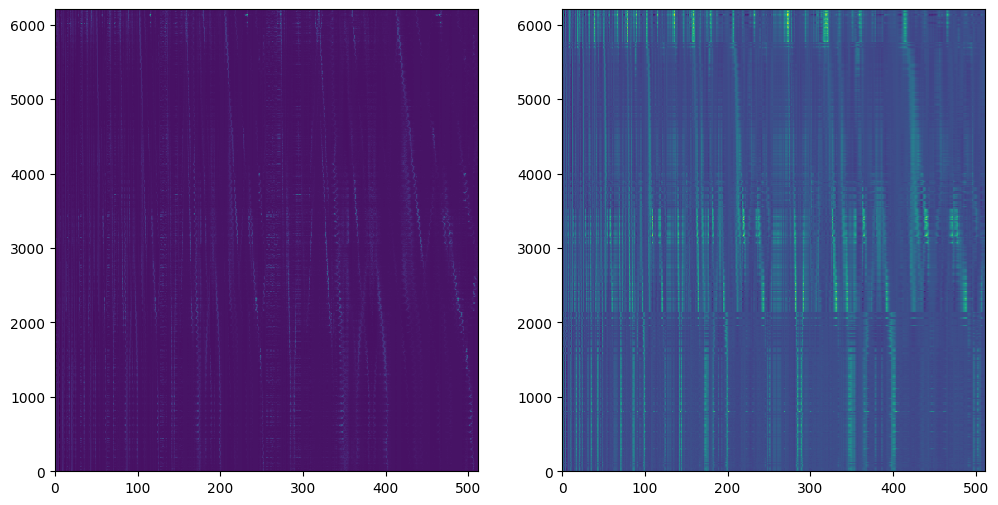

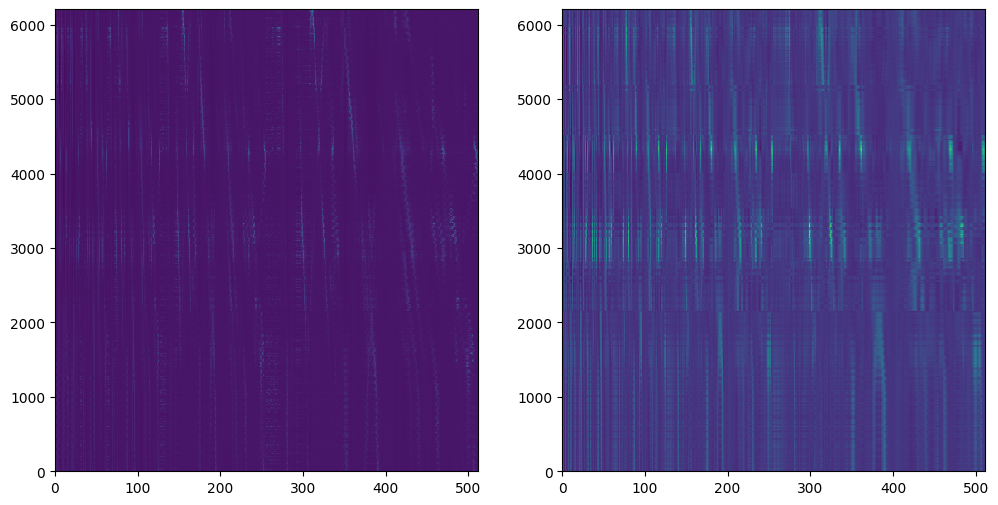

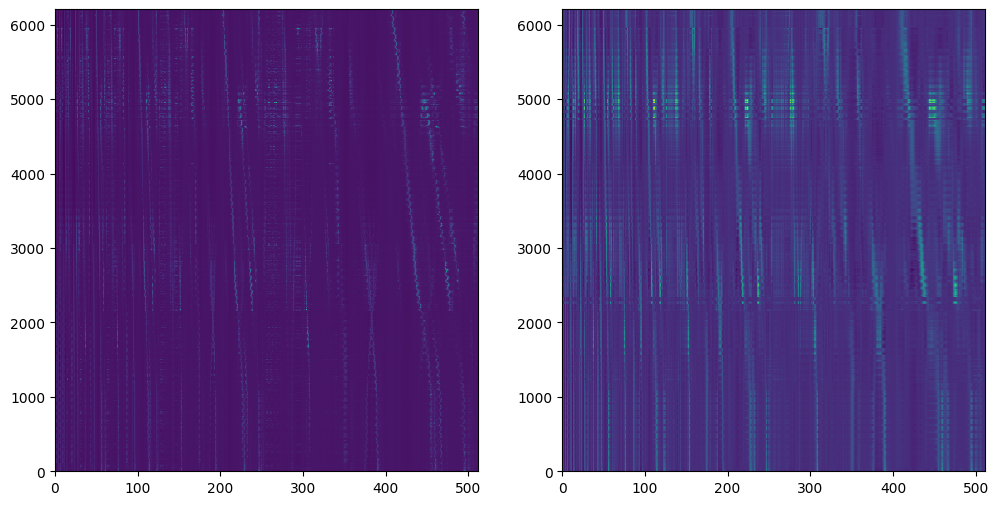

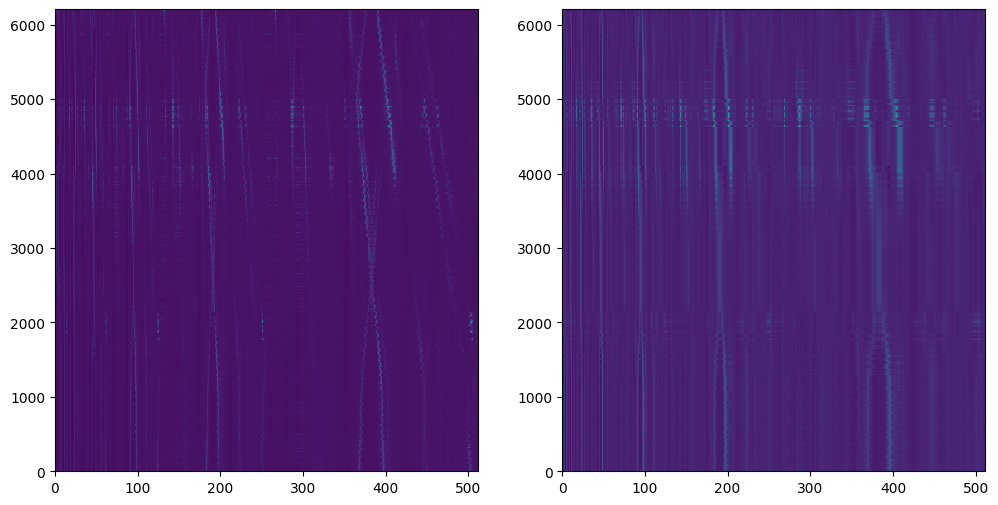

In [34]:
for cable in [0,1,2,3]:
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.pcolormesh(x_train[:, 0, cable, :])
    plt.subplot(1, 2, 2)
    plt.pcolormesh(x_rec_train[:, 0, cable, :])

In [35]:
dist_per_cable = {}
for cable in [0, 1, 2, 3]:
    dist_per_cable[cable+1] = [
        torch.nn.functional.mse_loss(vec, z_train[0, 0, cable, :])
        for vec in z_train[:, 0, cable, :]
    ]

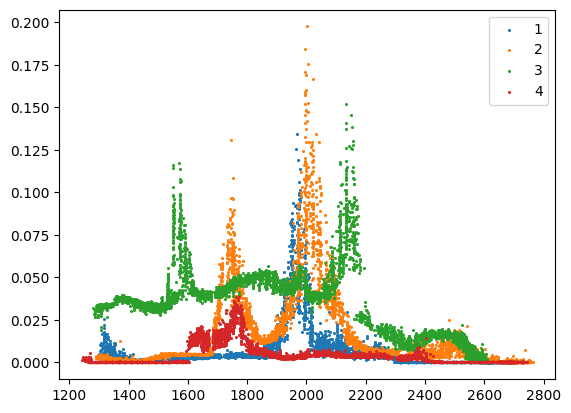

In [36]:
for cable in [1, 2, 3, 4]:
    plt.scatter(t_train[cable][:-1], dist_per_cable[cable], s=1.5)
plt.legend([1,2,3,4])

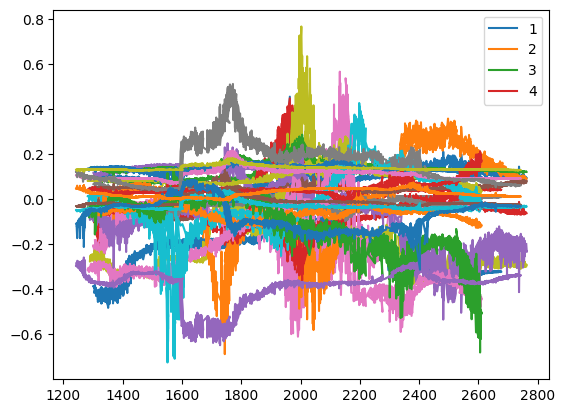

In [37]:
for cable in [1, 2, 3, 4]:
    plt.plot(t_train[cable][:-1], z_train[:,0,cable-1])
plt.legend([1,2,3,4])